<a href="https://colab.research.google.com/github/ancestor9/2026_Fall_Application-Deployment/blob/main/1120/CNN_YOLO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **[LangChain overview](https://docs.langchain.com/oss/python/langchain/overview?_gl=1*fd3frz*_gcl_au*MTIxMjA0ODMxOC4xNzg0NzgzODk1*_ga*MTc1NjgzNDc5NC4xNzYzMzQ3ODky*_ga_47WX3HKKY2*czE3OTE5NTkxMzAkbzExJGcxJHQxNzkxOTU5MjM2JGoxOSRsMCRoMA..)**

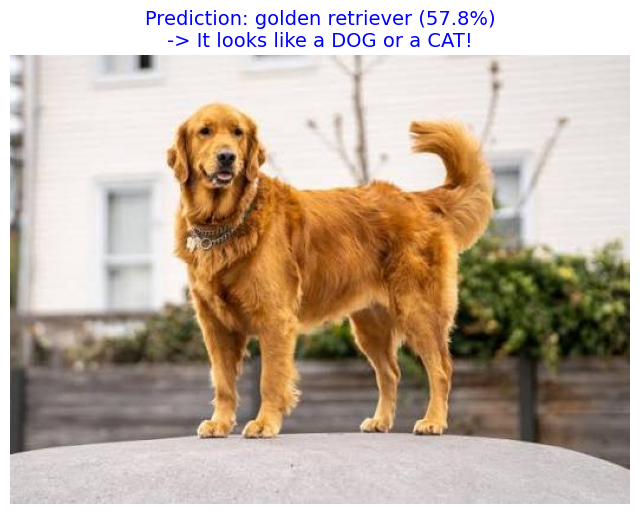

In [ ]:
import torch
from torchvision import models, transforms
from PIL import Image
import requests
from io import BytesIO
import matplotlib.pyplot as plt
import numpy as np

# @title 🐕🐈 **과제 템플릿: 사전학습 ResNet-18 활용 Zero-Training 분류**
# @markdown ##안내 및 사용법
# @markdown **1. 모델:** 이미 1000개의 클래스(개, 고양이 품종 다수 포함)를 분류하도록 학습된 **ResNet-18**을 사용합니다.
# @markdown **2. 목표:** 최종 출력층의 가중치를 *학습 없이* 그대로 사용하여, 업로드한 이미지를 사전학습 모델이 어떻게 분류하는지 확인합니다.
# @markdown **3. 실행 방법:** 아래 '분석 대상 이미지'에 URL을 입력한 후 셀을 실행합니다.

# ---
# [Part 1] 모델 및 클래스 정보 로드
# ---
# @markdown ###[Part 1] 모델 및 클래스 정보 로드
# @markdown ImageNet 데이터셋으로 사전학습된 ResNet-18 모델을 불러오고, 평가 모드(`eval()`)로 설정합니다.
# @markdown 1000개 클래스에 대한 이름 정보도 함께 불러옵니다.

# 사전학습된 ResNet-18 모델 로드
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model = model.to(device)
model.eval() # 추론 모드로 필수 설정

# ImageNet 클래스 라벨 텍스트 다운로드 및 매핑
LABELS_URL = "https://raw.githubusercontent.com/pytorch/hub/master/imagenet_classes.txt"
response = requests.get(LABELS_URL)
if 200 <= response.status_code < 300:
    categories = [s.strip() for s in response.text.splitlines()]
else:
    categories = [f"Class {i}" for i in range(1000)]
    print("Warning: Failed to load ImageNet labels.")

# ---
# [Part 2] 이미지 전처리 및 분류 함수 정의
# ---
# @markdown ###[Part 2] 이미지 분류 함수 정의
def classify_image_url(image_url):
    # a. 이미지 전처리 파이프라인
    preprocess = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        ),
    ])

    try:
        # b. User-Agent 헤더를 추가하여 보안 차단 우회
        headers = {
            'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/115.0.0.0 Safari/537.36'
        }
        response = requests.get(image_url, headers=headers, timeout=10)

        # HTTP 응답 상태 코드 확인 (200 OK가 아니면 에러 발생)
        response.raise_for_status()

        # 이미지 로드
        img = Image.open(BytesIO(response.content)).convert('RGB')

        # c. 전처리 및 입력 생성
        input_tensor = preprocess(img)
        input_batch = input_tensor.unsqueeze(0).to(device)

        # d. 추론 실행
        with torch.no_grad():
            output = model(input_batch)

        # e. 결과 해석
        probabilities = torch.nn.functional.softmax(output[0], dim=0)
        top_prob, top_catid = torch.topk(probabilities, 1)

        result = {
            'image': img,
            'class_name': categories[top_catid[0].item()],
            'probability': top_prob[0].item() * 100,
            'is_dog_cat': False
        }

        animal_keywords = ['dog', 'cat', 'puppy', 'kitten', 'terrier', 'retriever', 'spaniel']
        if any(keyword in result['class_name'].lower() for keyword in animal_keywords):
            result['is_dog_cat'] = True

        return result

    except Exception as e:
        print(f"Error: Could not load or classify image. {e}")
        return None

# ---
# [Part 3] 과제 실행 및 결과 시각화
# ---
# @markdown ###[Part 3] 분석 대상 이미지 및 과제 실행
# @markdown 아래 '이미지 URL'에 분석하고 싶은 이미지를 넣습니다.

# 과제 제출 예시: 골든 리트리버
image_url_dog = "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRWMKYq7ZwbLA7_4M3wuqGRFUjyUHlPFR__WtARVaeGvg&s=10" # @param {type:"string"}

# 함수 실행 및 결과 시각화
result = classify_image_url(image_url_dog)

if result:
    plt.figure(figsize=(8, 8))
    plt.imshow(result['image'])
    plt.axis('off')

    # 결과 텍스트 구성
    pred_text = f"Prediction: {result['class_name']} ({result['probability']:.1f}%)"
    if result['is_dog_cat']:
        pred_text += "\n-> It looks like a DOG or a CAT!"
    else:
        pred_text += "\n-> Classified as another class."

    plt.title(pred_text, fontsize=14, color='blue' if result['is_dog_cat'] else 'red')
    plt.show()

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings

0: 448x640 1 cat, 1 dog, 1 chair, 330.5ms
Speed: 18.7ms preprocess, 330.5ms inference, 24.7ms postprocess per image at shape (1, 3, 448, 640)
=== 탐지된 객체 목록 ===
- 클래스: cat (신뢰도: 88.3%)
- 클래스: dog (신뢰도: 67.9%)
- 클래스: chair (신뢰도: 65.3%)


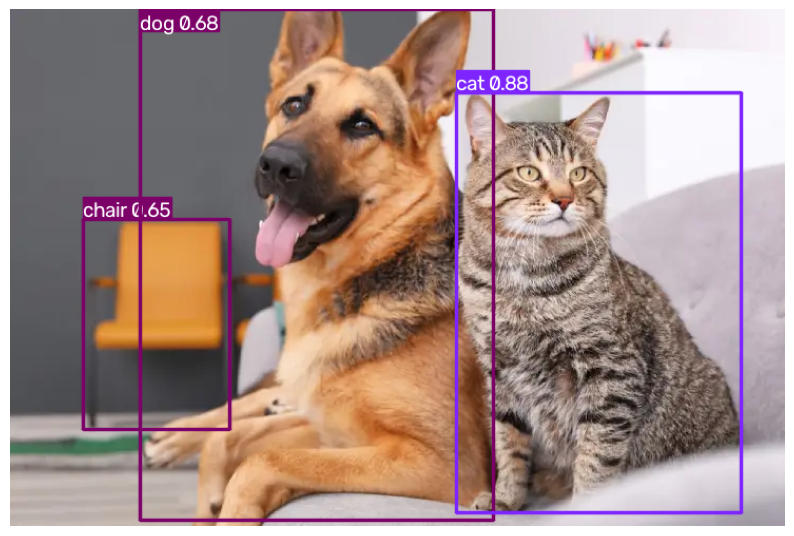

In [1]:
# 1. 필수 라이브러리 설치 (Colab 셀 실행)
!pip install ultralytics -q

import cv2
import requests
import numpy as np
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt
from ultralytics import YOLO

# @title 🐕🐈 **과제: 사전학습 YOLOv8을 활용한 객체 탐지(Object Detection)**

# 1. 사전학습된 YOLOv8 경량 모델(Nano 버전) 로드
# coco 데이터셋(80개 클래스: 사람, 차, 개, 고양이 등)으로 학습된 모델입니다.
model = YOLO('yolov8n.pt')

# 2. 이미지 다운로드 및 객체 탐지 함수
def detect_objects_from_url(image_url):
    headers = {
        'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36'
    }

    try:
        # 이미지 로드
        response = requests.get(image_url, headers=headers, timeout=10)
        response.raise_for_status()
        img = Image.open(BytesIO(response.content)).convert('RGB')

        # YOLO 추론 실행
        results = model(img)

        # 탐지 결과가 시각화된 이미지 추출 (Bounding Box 포함)
        annotated_frame = results[0].plot()
        # BGR -> RGB 변환 (OpenCV 기본 출력이 BGR이므로)
        annotated_frame = cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB)

        # 탐지된 객체 목록 출력
        boxes = results[0].boxes
        print("=== 탐지된 객체 목록 ===")
        for box in boxes:
            cls_id = int(box.cls[0])
            conf = float(box.conf[0])
            class_name = model.names[cls_id]
            print(f"- 클래스: {class_name} (신뢰도: {conf*100:.1f}%)")

        return annotated_frame

    except Exception as e:
        print(f"이미지 로드 중 오류 발생: {e}")
        return None

# 3. 테스트 이미지 실행 (개와 고양이가 같이 있는 이미지 등)
test_url = "https://www.webbox.co.uk/wp-content/uploads/2019/04/shutterstock_1095001973.webp" # @param {type:"string"}
result_img = detect_objects_from_url(test_url)

# 4. 결과 시각화
if result_img is not None:
    plt.figure(figsize=(10, 10))
    plt.imshow(result_img)
    plt.axis('off')
    plt.show()

In [2]:
# 1. Gradio 라이브러리 설치 및 임포트
!pip install gradio -q

import gradio as gr
import cv2
import numpy as np
from PIL import Image
from ultralytics import YOLO

# 2. YOLOv8 모델 로드
# 기존에 로드해둔 model이 메모리에 존재한다면 그것을 사용하고, 없다면 새로 불러옵니다.
try:
    yolo_model = model
except NameError:
    yolo_model = YOLO('yolov8n.pt')

# 3. 예측 함수 정의
def detect_objects_gradio(input_image):
    if input_image is None:
        return None, "이미지를 업로드해주세요."

    # YOLO 추론 실행
    results = yolo_model(input_image)

    # 결과 이미지 시각화 (Bounding Box 및 레이블 포함)
    annotated_frame = results[0].plot()
    # BGR -> RGB 변환
    annotated_frame = cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB)

    # 탐지된 객체 정보 텍스트 생성
    boxes = results[0].boxes
    detected_info = "=== 탐지된 객체 목록 ===\n"
    if len(boxes) == 0:
        detected_info += "탐지된 객체가 없습니다."
    else:
        for box in boxes:
            cls_id = int(box.cls[0])
            conf = float(box.conf[0])
            class_name = yolo_model.names[cls_id]
            detected_info += f"- {class_name}: {conf*100:.1f}%\n"

    return annotated_frame, detected_info

# 4. Gradio 인터페이스 정의 및 실행
demo = gr.Interface(
    fn=detect_objects_gradio,
    inputs=gr.Image(type="pil", label="이미지 업로드"),
    outputs=[
        gr.Image(type="numpy", label="객체 탐지 결과"),
        gr.Textbox(label="탐지 정보", lines=5)
    ],
    title="🐕🐈 YOLOv8 실시간 객체 탐지 데모",
    description="이미지를 드래그 앤 드롭하거나 클릭하여 업로드하면, YOLOv8 모델이 실시간으로 객체를 탐지하여 결과를 보여줍니다."
)

# share=True 설정을 통해 외부에서도 접속할 수 있는 임시 링크가 제공됩니다.
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5bf62eca7886ed501f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
